In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from data_wrangling import read_feature_set
from data_wrangling import create_day_ahead_forecast_split
from quantile_modelling import fit_q50_model, fit_q95_model, calculate_stress_metrics
from probabalistic_validation import pinball_loss, reliability

In [2]:
featured_filtered, candidate_features = read_feature_set()

target = "Balancing_energy_total"

issue_time = pd.Timestamp("2025-01-14 18:00", tz='UTC')

forecast_date = issue_time.normalize() + pd.Timedelta(days=1)
forecast_end = forecast_date + pd.Timedelta(days=1)

In [3]:
train_df, y_train_df, forecast_df = create_day_ahead_forecast_split(
    feature_df=featured_filtered,
    features=candidate_features['q95'],
    issue_time=issue_time,
    target="Balancing_energy_total",
)
candidate_features['q95']

['FR_CH_price_spread',
 'abs_load_residual_ramp_DA',
 'UA_thermal',
 'UA_hydro',
 'p_IDA3',
 'month',
 'load_residual_DA',
 'load_act',
 'RES_share_DA',
 'FR_IT-NORTH_price_spread']

In [4]:
y_test = featured_filtered["Balancing_energy_total"].loc[
        (featured_filtered.index >= forecast_date)
        & (featured_filtered.index < forecast_end)
    ]

y_test

Datetime
2025-01-15 00:00:00+00:00     648.94
2025-01-15 00:15:00+00:00     573.94
2025-01-15 00:30:00+00:00     628.94
2025-01-15 00:45:00+00:00     628.94
2025-01-15 01:00:00+00:00    1138.34
                              ...   
2025-01-15 22:45:00+00:00     382.57
2025-01-15 23:00:00+00:00     692.39
2025-01-15 23:15:00+00:00     911.03
2025-01-15 23:30:00+00:00    1004.03
2025-01-15 23:45:00+00:00    1208.71
Name: Balancing_energy_total, Length: 96, dtype: float64

### XGBoost

In [5]:
featured_filtered.index.max()

Timestamp('2026-08-31 23:45:00+0000', tz='UTC')

## Example: 1 issue date

In [6]:
issue_start = pd.Timestamp("2024-01-01 18:00", tz="UTC")

forecast_date = issue_start.normalize() + pd.Timedelta(days=1)
forecast_end = forecast_date + pd.Timedelta(days=1)

y_test = featured_filtered["Balancing_energy_total"].loc[
    (featured_filtered.index >= forecast_date)
    & (featured_filtered.index < forecast_end)
]

_, y_xgb_q50 = fit_q50_model(
    df=featured_filtered,
    features=candidate_features,
    issue_time=issue_time,
    model_type="xgb",
)

_, y_xgb_q95 = fit_q95_model(
    df=featured_filtered,
    features=candidate_features,
    issue_time=issue_time,
    model_type="xgb",
)

df_stress = calculate_stress_metrics(q50=y_xgb_q50, q95=y_xgb_q95)
df_stress

,q50,q95,stress_range,stress_ratio
Datetime,,,,
2025-01-15 00:00:00+00:00,1008.013794,2154.937256,1146.923462,2.137805
2025-01-15 00:15:00+00:00,1101.430298,2154.937256,1053.506958,1.956490
2025-01-15 00:30:00+00:00,1101.430298,2154.937256,1053.506958,1.956490
2025-01-15 00:45:00+00:00,1167.056519,2133.667480,966.610962,1.828247
2025-01-15 01:00:00+00:00,966.455383,2137.454590,1170.999268,2.211643
...,...,...,...,...
2025-01-15 22:45:00+00:00,927.133057,2227.751709,1300.618652,2.402839
2025-01-15 23:00:00+00:00,995.852417,2192.412598,1196.560181,2.201544
2025-01-15 23:15:00+00:00,916.537964,2192.412598,1275.874634,2.392059


In [7]:
# issue_start = pd.Timestamp("2024-01-01 18:00", tz="UTC")
# #issue_end = pd.Timestamp("2026-08-31 18:00", tz="UTC")
# issue_end = pd.Timestamp("2024-01-10 18:00", tz="UTC")

# issue_times = pd.date_range(
#     start=issue_start,
#     end=issue_end,
#     freq="D",
#     tz="UTC",
# )

# calibration_dfs = []
# y_test_dfs = []

# for issue_time in issue_times:

#     forecast_date = issue_time.normalize() + pd.Timedelta(days=1)
#     forecast_end = forecast_date + pd.Timedelta(days=1)

#     y_test = featured_filtered["Balancing_energy_total"].loc[
#         (featured_filtered.index >= forecast_date)
#         & (featured_filtered.index < forecast_end)
#     ]

#     _, y_xgb_q50 = fit_q50_model(
#         df=featured_filtered,
#         features=candidate_features,
#         issue_time=issue_time,
#         model_type="xgb",
#     )

#     _, y_xgb_q95 = fit_q95_model(
#         df=featured_filtered,
#         features=candidate_features,
#         issue_time=issue_time,
#         model_type="xgb",
#     )

#     df_stress = calculate_stress_metrics(y_xgb_q50, y_xgb_q95)

#     calibration_dfs.append(df_stress)
#     y_test_dfs.append(y_test)

# df_calibration = pd.concat(calibration_dfs).sort_index()
# df_nominal = pd.concat(y_test_dfs).sort_index()

In [8]:
featured_filtered.index.max()

Timestamp('2026-08-31 23:45:00+0000', tz='UTC')

In [9]:
from tqdm.auto import tqdm

issue_start = pd.Timestamp("2025-08-31 18:00", tz="UTC")
issue_end = pd.Timestamp("2026-08-30 18:00", tz="UTC")

issue_times = pd.date_range(
    start=issue_start,
    end=issue_end,
    freq="D",
    tz="UTC",
)

calibration_dfs = []
y_test_dfs = []

for issue_time in tqdm(
    issue_times,
    desc="Running daily forecasts",
    unit="day",
):

    forecast_date = issue_time.normalize() + pd.Timedelta(days=1)
    forecast_end = forecast_date + pd.Timedelta(days=1)

    y_test = featured_filtered["Balancing_energy_total"].loc[
        (featured_filtered.index >= forecast_date)
        & (featured_filtered.index < forecast_end)
    ]

    _, y_xgb_q50 = fit_q50_model(
        df=featured_filtered,
        features=candidate_features,
        issue_time=issue_time,
        model_type="xgb",
    )

    _, y_xgb_q95 = fit_q95_model(
        df=featured_filtered,
        features=candidate_features,
        issue_time=issue_time,
        model_type="xgb",
    )

    df_stress = calculate_stress_metrics(
        q50=y_xgb_q50,
        q95=y_xgb_q95,
    )

    calibration_dfs.append(df_stress)
    y_test_dfs.append(y_test)

df_calibration = pd.concat(calibration_dfs).sort_index()
df_nominal = pd.concat(y_test_dfs).sort_index()

c:\Users\Julia.Allen\WORKSPACE\repositories\MMI_European_Power_Modelling\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Running daily forecasts: 100%|██████████| 365/365 [13:02<00:00,  2.14s/day]


In [10]:
df_calibration

,q50,q95,stress_range,stress_ratio
Datetime,,,,
2025-09-01 00:00:00+00:00,957.349548,2150.854248,1193.504639,2.246676
2025-09-01 00:15:00+00:00,958.231934,2171.410156,1213.178223,2.266059
2025-09-01 00:30:00+00:00,958.231934,2146.930664,1188.698730,2.240513
2025-09-01 00:45:00+00:00,957.349548,2113.551758,1156.202148,2.207712
2025-09-01 01:00:00+00:00,951.173950,2066.254883,1115.080933,2.172321
...,...,...,...,...
2026-08-31 22:45:00+00:00,951.578552,1917.024536,965.445984,2.014573
2026-08-31 23:00:00+00:00,552.943665,2012.485840,1459.542236,3.639586
2026-08-31 23:15:00+00:00,603.728210,1947.273926,1343.545654,3.225415


In [11]:
df_calibration.to_pickle('./data/processed/xbg_predictions_25-26_v2.pickle')

In [12]:
df_nominal

Datetime
2025-09-01 00:00:00+00:00     942.3488
2025-09-01 00:15:00+00:00    1543.4040
2025-09-01 00:30:00+00:00    1962.8650
2025-09-01 00:45:00+00:00    1474.8140
2025-09-01 01:00:00+00:00     983.2080
                               ...    
2026-08-31 22:45:00+00:00     291.7800
2026-08-31 23:00:00+00:00      53.7572
2026-08-31 23:15:00+00:00     145.1060
2026-08-31 23:30:00+00:00      16.6444
2026-08-31 23:45:00+00:00     108.2743
Name: Balancing_energy_total, Length: 35040, dtype: float64

In [13]:
df_calibration.index.min(), df_calibration.index.max()

(Timestamp('2025-09-01 00:00:00+0000', tz='UTC'),
 Timestamp('2026-08-31 23:45:00+0000', tz='UTC'))

In [14]:
df_nominal.index.min(), df_nominal.index.max()

(Timestamp('2025-09-01 00:00:00+0000', tz='UTC'),
 Timestamp('2026-08-31 23:45:00+0000', tz='UTC'))

In [15]:
df_calibration.keys()

Index(['q50', 'q95', 'stress_range', 'stress_ratio'], dtype='str')

In [16]:
reliability_quantiles = reliability(df_calibration, df_nominal, quantile_cols=["q50", "q95"], quantiles=[0.50, 0.95])
reliability_quantiles

50    43.947631
95    94.782392
dtype: float64

Text(0, 0.5, 'Empirical')

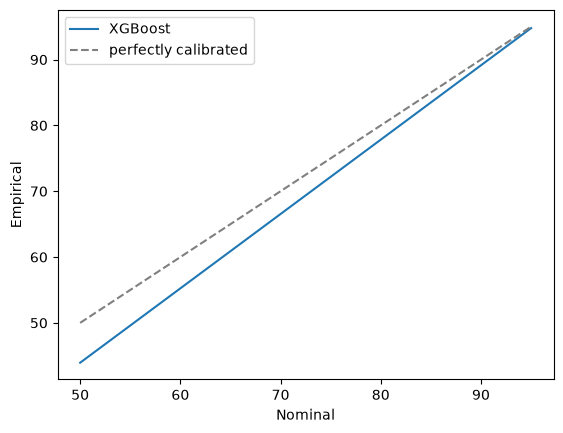

In [17]:
reliability_quantiles.plot(label='XGBoost')
plt.plot([50, 95], [50, 95], label='perfectly calibrated', ls='--', color='grey')
plt.legend()
plt.xlabel('Nominal')
plt.ylabel('Empirical')

In [18]:
# pinball_loss(y_true=y_test, y_pred=y_xgb_q50, quantile=0.5)
# pinball_loss(y_true=y_test, y_pred=y_xgb_q95, quantile=0.95)

### Linear

In [19]:
linear_model, y_linear_q50 = fit_q50_model(
    df=featured_filtered, 
    features=candidate_features, 
    issue_time=issue_time,
    model_type='linear'
)

pinball_loss(y_true=y_test, y_pred=y_linear_q50, quantile=0.5)

Columns containing NaNs:
wof_DA                       20920
abs_load_residual_ramp_DA        1
dtype: int64

Total NaN values: 20,921
Rows containing at least one NaN: 20,920
Total rows: 128,424
Print blocks: group
1    20920
dtype: int64
Original rows: 128,424
Remaining rows: 107,504
Dropped rows: 20,920


248.8789603817028

In [20]:
linear_model, y_linear_q95 = fit_q95_model(
    df=featured_filtered, 
    features=candidate_features, 
    issue_time=issue_time,
    model_type='linear'
)

pinball_loss(y_true=y_test, y_pred=y_linear_q95, quantile=0.95)

Columns containing NaNs:
p_IDA3                       91816
abs_load_residual_ramp_DA        1
dtype: int64

Total NaN values: 91,817
Rows containing at least one NaN: 91,816
Total rows: 128,424
Print blocks: group
1       51016
3          48
5          48
7          48
9          48
        ...  
1517       48
1519       48
1521       48
1523       48
1525       48
Length: 763, dtype: int64
Original rows: 128,424
Remaining rows: 36,608
Dropped rows: 91,816


ValueError: Input X contains NaN.
QuantileRegressor does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values